# RQ1 — Temporal Alignment

This notebook evaluates whether project-level Macro-F1 differs between commits sampled before and after each model's reported knowledge cutoff. The design is paired: every model is evaluated on the same projects in both temporal conditions, and the analyzed quantity is

$$
\Delta = \text{Post-cutoff Macro-F1} - \text{Pre-cutoff Macro-F1}.
$$

Positive values indicate higher post-cutoff performance and negative values indicate higher pre-cutoff performance. The analysis assesses temporal differences; it does not treat the cutoff as a causal intervention.

Models and projects are detected from the current CSV files. Newly added numeric model columns are incorporated automatically.


In [ ]:
from pathlib import Path

import numpy as np
import pandas as pd
import pingouin as pg
from IPython.display import Markdown, display


PROJECT_COLUMN = "project"

PRE_CUTOFF_PATH = Path("../metrics/pre_cutoff.csv")
POST_CUTOFF_PATH = Path("../metrics/post_cutoff.csv")

if not PRE_CUTOFF_PATH.exists():
    PRE_CUTOFF_PATH = Path("results/rq1/metrics/pre_cutoff.csv")

if not POST_CUTOFF_PATH.exists():
    POST_CUTOFF_PATH = Path("results/rq1/metrics/post_cutoff.csv")

if not PRE_CUTOFF_PATH.exists():
    raise FileNotFoundError("Could not find pre_cutoff.csv.")

if not POST_CUTOFF_PATH.exists():
    raise FileNotFoundError("Could not find post_cutoff.csv.")


df_pre_raw = pd.read_csv(
    PRE_CUTOFF_PATH,
    index_col=PROJECT_COLUMN,
)

df_post_raw = pd.read_csv(
    POST_CUTOFF_PATH,
    index_col=PROJECT_COLUMN,
)


if df_pre_raw.index.duplicated().any():
    duplicates = (
        df_pre_raw.index[df_pre_raw.index.duplicated()]
        .astype(str)
        .tolist()
    )
    raise ValueError(
        f"Duplicate project identifiers in pre-cutoff data: {duplicates}"
    )

if df_post_raw.index.duplicated().any():
    duplicates = (
        df_post_raw.index[df_post_raw.index.duplicated()]
        .astype(str)
        .tolist()
    )
    raise ValueError(
        f"Duplicate project identifiers in post-cutoff data: {duplicates}"
    )


models_only_pre = [
    column
    for column in df_pre_raw.columns
    if column not in df_post_raw.columns
]

models_only_post = [
    column
    for column in df_post_raw.columns
    if column not in df_pre_raw.columns
]

common_columns = df_pre_raw.columns.intersection(
    df_post_raw.columns
)

if len(common_columns) == 0:
    raise ValueError(
        "No common model columns were found between the two datasets."
    )


models = list(common_columns)

for column in models:
    pre_numeric = pd.to_numeric(
        df_pre_raw[column],
        errors="coerce",
    )
    post_numeric = pd.to_numeric(
        df_post_raw[column],
        errors="coerce",
    )

    pre_observed = df_pre_raw[column].notna()
    post_observed = df_post_raw[column].notna()

    if (
        pre_observed.any()
        and not pre_numeric.loc[pre_observed].notna().all()
    ):
        raise ValueError(
            f"Pre-cutoff model column '{column}' contains non-numeric values."
        )

    if (
        post_observed.any()
        and not post_numeric.loc[post_observed].notna().all()
    ):
        raise ValueError(
            f"Post-cutoff model column '{column}' contains non-numeric values."
        )

    df_pre_raw[column] = pre_numeric
    df_post_raw[column] = post_numeric


projects_only_pre = (
    df_pre_raw.index
    .difference(df_post_raw.index)
    .tolist()
)

projects_only_post = (
    df_post_raw.index
    .difference(df_pre_raw.index)
    .tolist()
)

common_projects = df_pre_raw.index.intersection(
    df_post_raw.index
)


df_pre = df_pre_raw.loc[
    common_projects,
    models,
].copy()

df_post = df_post_raw.loc[
    common_projects,
    models,
].copy()


incomplete_mask = (
    df_pre.isna().any(axis=1)
    | df_post.isna().any(axis=1)
)

removed_projects = (
    common_projects[incomplete_mask.to_numpy()]
    .astype(str)
    .tolist()
)

df_pre = df_pre.loc[~incomplete_mask].copy()
df_post = df_post.loc[~incomplete_mask].copy()

if len(df_pre) < 3:
    raise ValueError(
        "Fewer than three complete paired projects remain."
    )


print(f"Pre-cutoff source: {PRE_CUTOFF_PATH}")
print(f"Post-cutoff source: {POST_CUTOFF_PATH}")
print(f"Complete paired projects retained: {len(df_pre)}")
print(f"Detected models ({len(models)}): {models}")

if removed_projects:
    print(
        "Projects removed by complete-case paired filtering: "
        f"{removed_projects}"
    )

if models_only_pre:
    print(
        "Columns present only in pre-cutoff data: "
        f"{models_only_pre}"
    )

if models_only_post:
    print(
        "Columns present only in post-cutoff data: "
        f"{models_only_post}"
    )

if projects_only_pre:
    print(
        "Projects present only in pre-cutoff data: "
        f"{projects_only_pre}"
    )

if projects_only_post:
    print(
        "Projects present only in post-cutoff data: "
        f"{projects_only_post}"
    )

display(df_pre.head())
display(df_post.head())

## Automatic paired analysis

The normality assumption of a paired Student's $t$-test concerns the paired differences, not the isolated pre- and post-cutoff distributions. Shapiro–Wilk is therefore applied to each model's $\Delta$ distribution.

The prespecified decision rule is:

1. if normality is not rejected for every model, use paired Student's $t$-tests and Hedges' $g_{av}$;
2. otherwise, use Wilcoxon signed-rank tests and matched-pairs rank-biserial correlations ($r_{rb}$) for all models;
3. adjust the family of model-level $p$-values with Holm's procedure;
4. report unadjusted 95% confidence intervals for mean $\Delta$ only on the parametric route.

Mauchly's test is not required because each model has only two paired temporal conditions.


In [ ]:
from scipy.stats import shapiro, t, ttest_rel


def _format_decimal(value, digits=3):
    text = f"{float(value):.{digits}f}"
    if text.startswith("0."):
        return text[1:]
    if text.startswith("-0."):
        return "-" + text[2:]
    return text


def _format_p_markdown(p_value):
    p_value = float(p_value)
    if p_value < 0.001:
        return r"$p<.001$"
    return f"$p={_format_decimal(p_value)}$"


def _format_p_plain(p_value, digits=4):
    p_value = float(p_value)
    if p_value < 0.001:
        return "<.001"
    return f"{p_value:.{digits}f}".lstrip("0")


def _effect_magnitude(effect, route):
    absolute_effect = abs(float(effect))

    if route == "parametric":
        if absolute_effect < 0.2:
            return "Negligible"
        if absolute_effect < 0.5:
            return "Small"
        if absolute_effect < 0.8:
            return "Medium"
        return "Large"

    if absolute_effect < 0.1:
        return "Negligible"
    if absolute_effect < 0.3:
        return "Small"
    if absolute_effect < 0.5:
        return "Medium"
    return "Large"


def run_temporal_alignment_analysis(
    pre_data,
    post_data,
    alpha=0.05,
):
    if not pre_data.index.equals(post_data.index):
        raise ValueError("Pre and post project indices are not aligned.")
    if not pre_data.columns.equals(post_data.columns):
        raise ValueError("Pre and post model columns are not aligned.")

    differences = post_data - pre_data

    shapiro_rows = []
    for model in differences.columns:
        statistic, p_value = shapiro(differences[model])
        shapiro_rows.append({
            "Model": model,
            "N": int(differences[model].notna().sum()),
            "W": float(statistic),
            "p": float(p_value),
            "Normality not rejected": bool(p_value >= alpha),
        })

    shapiro_results = pd.DataFrame(shapiro_rows).set_index("Model")
    all_normal = bool(
        shapiro_results["Normality not rejected"].all()
    )
    route = "parametric" if all_normal else "non-parametric"

    result_rows = []

    for model in differences.columns:
        pre_values = pre_data[model].to_numpy()
        post_values = post_data[model].to_numpy()
        delta = differences[model]
        n = len(delta)

        mean_pre = float(np.mean(pre_values))
        mean_post = float(np.mean(post_values))
        mean_delta = float(delta.mean())
        sd_delta = float(delta.std(ddof=1))

        if route == "parametric":
            test_statistic, p_raw = ttest_rel(
                post_values,
                pre_values,
            )

            if np.allclose(post_values - pre_values, 0):
                hedges_g = 0.0
            else:
                hedges_g = pg.compute_effsize(
                    post_values,
                    pre_values,
                    paired=True,
                    eftype="hedges",
                )

            standard_error = delta.sem()
            if standard_error == 0:
                ci_lower = mean_delta
                ci_upper = mean_delta
            else:
                ci_lower, ci_upper = t.interval(
                    0.95,
                    df=n - 1,
                    loc=mean_delta,
                    scale=standard_error,
                )

            statistic_name = "t"
            effect_name = "Hedges' g"
            effect = float(hedges_g)

        else:
            if np.allclose(post_values - pre_values, 0):
                test_statistic = 0.0
                p_raw = 1.0
                rbc = 0.0
            else:
                wilcoxon = pg.wilcoxon(
                    post_values,
                    pre_values,
                    alternative="two-sided",
                ).iloc[0]
                test_statistic = float(wilcoxon["W_val"])
                p_raw = float(wilcoxon["p_val"])
                rbc = float(wilcoxon["RBC"])

            ci_lower = np.nan
            ci_upper = np.nan
            statistic_name = "W"
            effect_name = "RBC"
            effect = rbc

        result_rows.append({
            "Model": model,
            "N": n,
            "Mean Pre": mean_pre,
            "Mean Post": mean_post,
            "Mean Delta": mean_delta,
            "SD Delta": sd_delta,
            "CI95 Lower": ci_lower,
            "CI95 Upper": ci_upper,
            "Statistic name": statistic_name,
            "Statistic": float(test_statistic),
            "p_raw": float(p_raw),
            "Effect name": effect_name,
            "Effect": effect,
        })

    results = pd.DataFrame(result_rows).set_index("Model")

    reject, corrected_p = pg.multicomp(
        results["p_raw"].to_numpy(),
        alpha=alpha,
        method="holm",
    )
    results["p_Holm"] = corrected_p
    results["Significant"] = reject
    results["Effect magnitude"] = results["Effect"].map(
        lambda value: _effect_magnitude(value, route)
    )

    improvement_rows = []
    for model in differences.columns:
        delta = differences[model]
        improved = int((delta > 0).sum())
        worsened = int((delta < 0).sum())
        unchanged = int((delta == 0).sum())
        total = len(delta)

        improvement_rows.append({
            "Model": model,
            "Improved (n)": improved,
            "Improved (%)": 100 * improved / total,
            "Worsened (n)": worsened,
            "Worsened (%)": 100 * worsened / total,
            "Unchanged (n)": unchanged,
            "Unchanged (%)": 100 * unchanged / total,
        })

    improvement = pd.DataFrame(improvement_rows).set_index("Model")

    print("PAIRED DIFFERENCE NORMALITY")
    shapiro_display = shapiro_results.copy()
    shapiro_display["W"] = shapiro_display["W"].round(4)
    shapiro_display["p"] = shapiro_display["p"].map(
        _format_p_plain
    )
    display(shapiro_display)

    print(f"SELECTED ROUTE: {route}")
    print("HOLM-CORRECTED MODEL-LEVEL RESULTS")

    result_display = results.copy()
    result_display["p_raw"] = result_display["p_raw"].map(
        _format_p_plain
    )
    result_display["p_Holm"] = result_display["p_Holm"].map(
        _format_p_plain
    )
    display(result_display.round({
        "Mean Pre": 4,
        "Mean Post": 4,
        "Mean Delta": 4,
        "SD Delta": 4,
        "CI95 Lower": 4,
        "CI95 Upper": 4,
        "Statistic": 4,
        "Effect": 4,
    }))

    print("PROJECT-LEVEL DIRECTION OF CHANGE")
    display(improvement.round({
        "Improved (%)": 1,
        "Worsened (%)": 1,
        "Unchanged (%)": 1,
    }))

    return {
        "route": route,
        "differences": differences,
        "shapiro": shapiro_results,
        "results": results,
        "improvement": improvement,
        "alpha": alpha,
    }


def generate_temporal_alignment_report(
    analysis,
    title="RQ1 interpretation generated from the current data",
):
    route = analysis["route"]
    results = analysis["results"]
    shapiro_results = analysis["shapiro"]
    significant = results.loc[results["Significant"]]

    if route == "parametric":
        assumption_text = (
            "Shapiro–Wilk did not reject normality for any model's "
            "paired project-level differences. Paired Student's "
            "$t$-tests were therefore used, with Holm correction "
            "across the model family and Hedges' $g$ effect sizes."
        )
        test_name = "paired Student's $t$-test"
        statistic_symbol = "$t$"
        effect_label = "Hedges' $g$"
    else:
        failed_models = shapiro_results.index[
            ~shapiro_results["Normality not rejected"]
        ].tolist()
        assumption_text = (
            "Shapiro–Wilk rejected normality for at least one "
            "paired-difference distribution ("
            + ", ".join(failed_models)
            + "). Wilcoxon signed-rank tests were therefore used "
            "for all models, with Holm correction and matched-pairs "
            "rank-biserial correlations."
        )
        test_name = "Wilcoxon signed-rank test"
        statistic_symbol = "$W$"
        effect_label = "$r_{rb}$"

    delta_min = float(results["Mean Delta"].min())
    delta_max = float(results["Mean Delta"].max())

    if significant.empty:
        inference_text = (
            "No model exhibited a statistically significant "
            "pre- versus post-cutoff difference after Holm "
            "correction."
        )
    else:
        significant_lines = []
        for model, row in significant.iterrows():
            direction = (
                "higher post-cutoff performance"
                if row["Mean Delta"] > 0
                else "higher pre-cutoff performance"
            )
            significant_lines.append(
                f"- **{model}** showed {direction} "
                f"({statistic_symbol} = "
                f"{row['Statistic']:.2f}, "
                f"{_format_p_markdown(row['p_Holm'])}, "
                f"{effect_label} = {row['Effect']:.3f})"
            )
        inference_text = (
            "The following models remained significant after Holm "
            "correction:\n\n" + "\n".join(significant_lines)
        )

    ci_text = ""
    if route == "parametric":
        all_include_zero = bool(
            (
                (results["CI95 Lower"] <= 0)
                & (results["CI95 Upper"] >= 0)
            ).all()
        )
        if all_include_zero:
            ci_text = (
                "All unadjusted 95% confidence intervals for mean "
                "$\\Delta$ included zero."
            )
        else:
            excluded_zero = results.index[
                ~(
                    (results["CI95 Lower"] <= 0)
                    & (results["CI95 Upper"] >= 0)
                )
            ].tolist()
            ci_text = (
                "The unadjusted 95% confidence interval excluded zero "
                "for: " + ", ".join(excluded_zero) + "."
            )

    if significant.empty:
        conclusion = (
            "The analysis found no statistical evidence that "
            "temporal alignment with the models' reported knowledge "
            "cutoffs systematically changed classification "
            "performance. This is an absence-of-evidence conclusion, "
            "not a demonstration of equivalence."
        )
    else:
        conclusion = (
            "Temporal differences were detected only for the models "
            "listed above; the direction and magnitude should be "
            "interpreted from the paired estimates."
        )

    report = f"""
## {title}

### Statistical approach

{assumption_text}

### Temporal differences

Mean project-level differences ranged from
{_format_decimal(delta_min)} to {_format_decimal(delta_max)} Macro-F1.
{inference_text} {ci_text}

### Data-driven interpretation

{conclusion}
"""
    return textwrap.dedent(report)


## Execute the analysis

The statistical tables and interpretation below are generated from the currently loaded pre- and post-cutoff datasets. No numerical result is stored as static notebook text.


In [3]:
import textwrap

rq1_analysis = run_temporal_alignment_analysis(
    pre_data=df_pre,
    post_data=df_post,
)

rq1_report = generate_temporal_alignment_report(rq1_analysis)
display(Markdown(rq1_report))

PAIRED DIFFERENCE NORMALITY


,N,W,p,Normality not rejected
Model,,,,
gemma_3_27b,30,0.9757,.7039,True
granite_3_3_8b,30,0.9558,.2403,True
llama_3_2_vision_11b,30,0.9587,.2872,True
magistral_24b,30,0.9622,.3522,True
mistral_small_3_2_24b,30,0.9616,.3410,True
phi_4_rp_14b,30,0.9627,.3633,True
qwq_32b,30,0.9448,.1226,True


SELECTED ROUTE: parametric
HOLM-CORRECTED MODEL-LEVEL RESULTS


,N,Mean Pre,Mean Post,Mean Delta,SD Delta,CI95 Lower,CI95 Upper,Statistic name,Statistic,p_raw,Effect name,Effect,p_Holm,Significant,Effect magnitude
Model,,,,,,,,,,,,,,,
gemma_3_27b,30,0.3483,0.3660,0.0177,0.1171,-0.0261,0.0614,t,0.8262,.4155,Hedges' g,0.1827,1.0000,False,Negligible
granite_3_3_8b,30,0.2979,0.3076,0.0097,0.0963,-0.0262,0.0457,t,0.5544,.5835,Hedges' g,0.1235,1.0000,False,Negligible
llama_3_2_vision_11b,30,0.2449,0.2504,0.0055,0.0799,-0.0244,0.0353,t,0.3752,.7103,Hedges' g,0.0684,1.0000,False,Negligible
magistral_24b,30,0.3926,0.4094,0.0168,0.1157,-0.0264,0.0600,t,0.7941,.4336,Hedges' g,0.1597,1.0000,False,Negligible
mistral_small_3_2_24b,30,0.3840,0.4065,0.0225,0.1123,-0.0194,0.0645,t,1.0993,.2807,Hedges' g,0.2535,1.0000,False,Small
phi_4_rp_14b,30,0.3295,0.3290,-0.0005,0.1336,-0.0504,0.0494,t,-0.0206,.9837,Hedges' g,-0.0054,1.0000,False,Negligible
qwq_32b,30,0.4735,0.4743,0.0007,0.1250,-0.0459,0.0474,t,0.0328,.9740,Hedges' g,0.0071,1.0000,False,Negligible


PROJECT-LEVEL DIRECTION OF CHANGE


,Improved (n),Improved (%),Worsened (n),Worsened (%),Unchanged (n),Unchanged (%)
Model,,,,,,
gemma_3_27b,17,56.7,13,43.3,0,0.0
granite_3_3_8b,17,56.7,13,43.3,0,0.0
llama_3_2_vision_11b,16,53.3,14,46.7,0,0.0
magistral_24b,18,60.0,12,40.0,0,0.0
mistral_small_3_2_24b,14,46.7,16,53.3,0,0.0
phi_4_rp_14b,16,53.3,14,46.7,0,0.0
qwq_32b,14,46.7,16,53.3,0,0.0



## RQ1 interpretation generated from the current data

### Statistical approach

Shapiro–Wilk did not reject normality for any model's paired project-level differences. Paired Student's $t$-tests were therefore used, with Holm correction across the model family and Hedges' $g$ effect sizes.

### Temporal differences

Mean project-level differences ranged from
-.001 to .023 Macro-F1.
No model exhibited a statistically significant pre- versus post-cutoff difference after Holm correction. All unadjusted 95% confidence intervals for mean $\Delta$ included zero.

### Data-driven interpretation

The analysis found no statistical evidence that temporal alignment with the models' reported knowledge cutoffs systematically changed classification performance. This is an absence-of-evidence conclusion, not a demonstration of equivalence.


## Paired-difference visualization

The figure displays the distribution of $\Delta=\text{Post}-\text{Pre}$ across projects. The horizontal line represents no temporal difference. This visualization preserves the paired analysis by plotting the derived project-level differences directly.


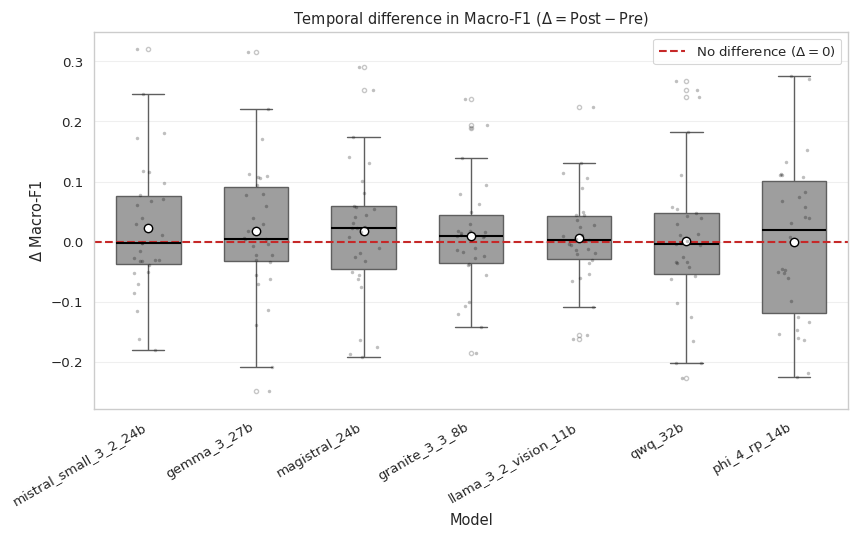

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns

differences = rq1_analysis["differences"]
model_order = differences.mean().sort_values(ascending=False).index

plot_data = (
    differences[model_order]
    .rename_axis("project")
    .reset_index()
    .melt(
        id_vars="project",
        var_name="Model",
        value_name="Delta",
    )
)

sns.set_theme(
    style="whitegrid",
    context="paper",
    font_scale=1.1,
    rc={"grid.alpha": 0.3},
)

figure_width = max(8, 1.25 * len(model_order))
fig, ax = plt.subplots(figsize=(figure_width, 5.5))

sns.boxplot(
    data=plot_data,
    x="Model",
    y="Delta",
    order=model_order,
    color="#9E9E9E",
    width=0.6,
    showmeans=True,
    medianprops={"linewidth": 1.5, "color": "black"},
    meanprops={
        "marker": "o",
        "markerfacecolor": "white",
        "markeredgecolor": "black",
        "markersize": 6,
    },
    flierprops={
        "marker": "o",
        "markersize": 3,
        "alpha": 0.35,
    },
    ax=ax,
)

sns.stripplot(
    data=plot_data,
    x="Model",
    y="Delta",
    order=model_order,
    color="black",
    alpha=0.25,
    size=2.5,
    jitter=0.15,
    ax=ax,
)

ax.axhline(
    0,
    color="#C62828",
    linestyle="--",
    linewidth=1.5,
    label=r"No difference ($\Delta=0$)",
)

ax.set_title(
    r"Temporal difference in Macro-F1 ($\Delta=\mathrm{Post}-\mathrm{Pre}$)"
)
ax.set_xlabel("Model")
ax.set_ylabel(r"$\Delta$ Macro-F1")
ax.tick_params(axis="x", rotation=30)
for label in ax.get_xticklabels():
    label.set_horizontalalignment("right")
ax.legend(loc="best", frameon=True)

fig.tight_layout()
plt.show()


## Reproducibility notes

- The notebook aligns projects and models by identifier before calculating differences.
- Projects removed because of incomplete pairing are printed explicitly.
- Holm correction is applied across the number of models detected in the current files.
- The reported 95% confidence intervals are individual, unadjusted intervals for mean paired differences.
- If the data change, rerun all cells so that the route, tests, effects, intervals, tables, narrative, and figure are regenerated.
